In [67]:
import pandas as pd

df = pd.read_csv(r"C:\Users\rcrds\Desktop\Ironhack\Labs\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [68]:
# Part1.1
group_freq = df.groupby("category")["uid"].agg("count").sort_values(ascending=False).reset_index()
group_freq5 = group_freq.head(5)
group_freq5

,category,uid
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


C:\Users\rcrds\AppData\Local\Temp\ipykernel_33160\3254392224.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_freq5.category, y=group_freq5.uid, palette="Set3", );


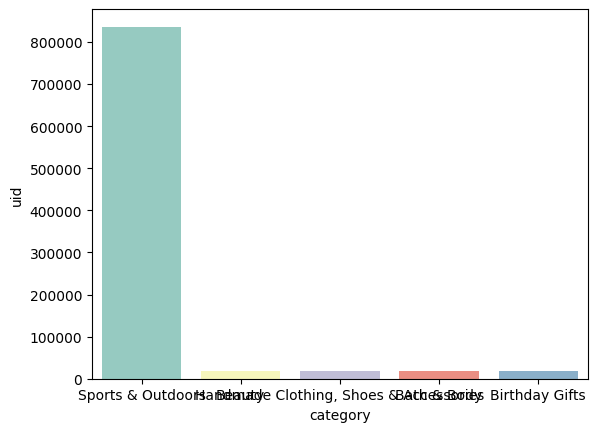

In [69]:
# Part1.2

import seaborn as sns

sns.barplot(x=group_freq5.category, y=group_freq5.uid, palette="Set3", );

<Axes: ylabel='uid'>

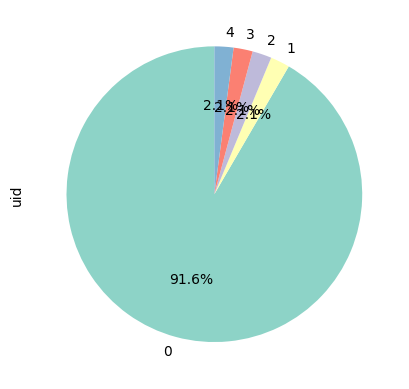

In [70]:
group_freq5.uid.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

In [71]:
# Part2.1

df_price_mean = round(df.describe().price,2)["mean"]
df_price_mean


np.float64(89.24)

In [72]:

df_price_median = df.price.median()
df_price_median

19.09

In [73]:
df_price_mode = df.price.mode()
df_price_mode

0    9.99
Name: price, dtype: float64

In [74]:
print("Answer: Average price of 89.24 is quite above the mode (9.99). It indicates a negative skew, probably due to high outlier(s) ")

Answer: Average price of 89.24 is quite above the mode (9.99). It indicates a negative skew, probably due to high outlier(s) 


In [75]:
# Part2.2
round(df.describe().price,2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [76]:
q25 = round(df.describe().price,2)["25%"]
q25

np.float64(9.99)

In [77]:
q50 = round(df.describe().price,2)["50%"]
q50

np.float64(19.09)

In [78]:
q75 = round(df.describe().price,2)["75%"]
q75

np.float64(45.99)

In [79]:
df_price_std = round(df.describe().price,2)["std"]
df_price_std

np.float64(345.61)

In [80]:
df_price_var = round(df.price.var(),2)
df_price_var

119445.49

In [81]:
df.price.skew()

np.float64(27.49297756628037)

In [82]:
print("Answer: Price are quite spread. Std is multiple times higher than mean and even above quartile 75. All trends in a way of one or more outliers skewing the results. Such was confirmed by the ske score of 27.5! ")

Answer: Price are quite spread. Std is multiple times higher than mean and even above quartile 75. All trends in a way of one or more outliers skewing the results. Such was confirmed by the ske score of 27.5! 


Answer: Either with small bin size or big bin sizes, it's allwayes hard to read the histogram without removing the outliers or defining categories.


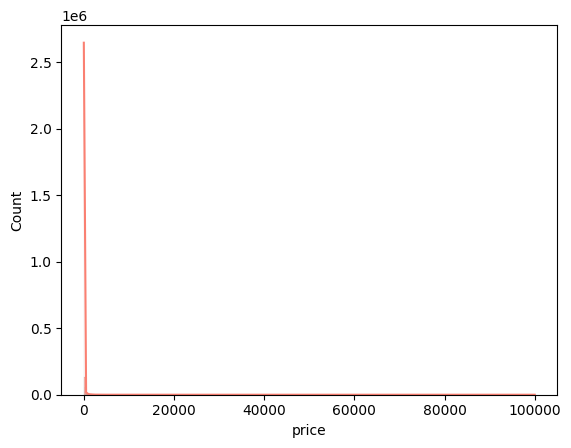

In [103]:
# Part2.3

sns.histplot(df.price, kde=True, bins=1000, color="salmon")
print("Answer: Either with small bin size or big bin sizes, it's always hard to read the histogram without removing the outliers or defining categories.")

<Axes: ylabel='price'>

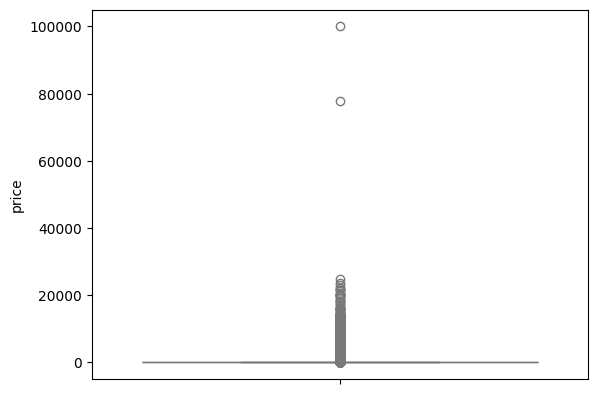

In [84]:
sns.boxplot(data = df.price, color="lightblue")

In [85]:
print("Answer: There are some outliers over the normal max range. Specially a record near 100000 and another at 80000")

Answer: There are some outliers over the normal max range. Specially a record near 100000 and another at 80000


In [86]:
#Part3.1
rating_mean = round(df.stars.mean(),2)
rating_mean


np.float64(2.15)

In [87]:

rating_median = round(df.stars.median(),2)
rating_median


0.0

In [88]:

rating_mode = round(df.stars.mode(),2)
rating_mode

0    0.0
Name: stars, dtype: float64

In [89]:
print("Answer: We can see from the median and also the mode that quite often the rating is 0. Which may indicate that people submit their review without filling this (instead of really feeling that should be rated with 0)")

Answer: We can see from the median and also the mode that quite often the rating is 0. Which may indicate that people submit their review without filling this (instead of really feeling that should be rated with 0)


In [90]:
#Part3.2

q25 = round(df.stars.describe(),2)["25%"]
q25


np.float64(0.0)

In [91]:
q50 = round(df.stars.describe(),2)["50%"]
q50

np.float64(0.0)

In [92]:
q75= round(df.stars.describe(),2)["75%"]
q75

np.float64(4.4)

In [93]:
df_stars_std = round(df.stars.std(),2)
df_stars_std

2.19

In [94]:
df_stars_var = round(df.stars.var(),2)
df_stars_var

4.82

In [95]:
print("Answer: Over 50% of the records are '0' (we can see that by the quartile 50%). ")

Answer: Over 50% of the records are '0' (we can see that by the quartile 50%). 


In [96]:
#Part3.3

stars_skew = df.stars.skew()
stars_skew

np.float64(0.08120735761080881)

In [97]:

stars_kurtosis = df.stars.kurtosis()
stars_kurtosis

np.float64(-1.9260061280432994)

In [ ]:
print("Answer: The skew is nearly 0 but slightly positive. However, kurtosis is nearly -2 wich shows that is low kurtosis and has fewer outliers. WHich can make sense, since the strangest value '0' is actually the mode... ")

Answer: The skew is nearly  


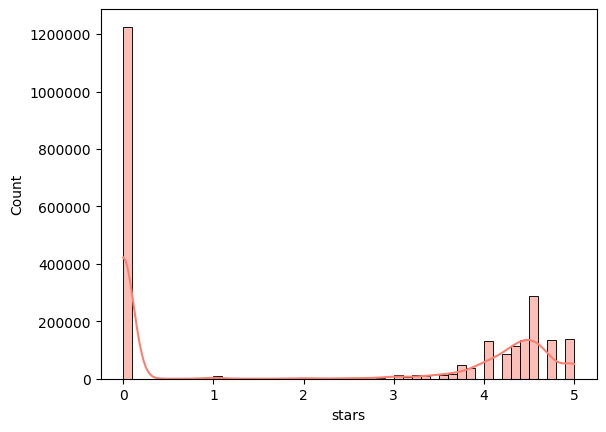

In [106]:
#Part3.4
import matplotlib.pyplot as plt
sns.histplot(round(df.stars,2), kde=True, bins=50, color="salmon")
ax = plt.gca()
ax.ticklabel_format(style='plain', axis='y')
plt.show()

In [ ]:
print("Answer: As expected the value '0' is by far the one with the highest count (4 times more than the 2nd most frequent)  ")